# Joint bias in $A_B$ and $F$ from neglecting hyperillumination

The analysis of `01_albedo_bias.ipynb` extended to heat redistribution: the noiseless hyperillumination truth, which has no redistribution, fitted with `naive_redist` (the point-source model with Kreidberg & Loeb 2016 redistribution) with $A_B$, $F$ and the baseline free. The truth has $F = 0$, so the fitted $F$ is its own bias; the $A_B$-only fit of `01_albedo_bias` is shown alongside.

In [1]:
import numpy as np
import contextlib, io
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from joblib.externals.loky import get_reusable_executor  # to recycle the SPIDERMAN workers between parallel blocks
with contextlib.redirect_stdout(io.StringIO()):          # mute "no spidermanrc file detected"
    import fspiderman
from hyperphase.defaults import (A_B_FIT_BOUNDS, DEFAULT_A, DEFAULT_A_B, DEFAULT_N_BINS, DEFAULT_N_LA, DEFAULT_N_LO, DEFAULT_N_ORBITS, DEFAULT_U,
                                 DEFAULT_U_BOL)
from hyperphase.irradiance import surface_temperature
from hyperphase.plotting.irradiance import stellar_flux_line
from hyperphase.model import ConstantBandAlbedo, FittingConfig, model_pcurve
from hyperphase.phasecurve import full_PhaseCurve
from hyperphase.bands import filter_lambda, filter_loc, JWST_BANDS
from hyperphase.orbit import transit_duration_t14
import pandas as pd
from hyperphase.bias.detectors import retrieval_cfg
from hyperphase.bias.fisher import measurability
from hyperphase.bias.fits import bin_curve, chi2_landscape, chi2_region, fit_chi2, fit_naive, fit_redist
from hyperphase.bias.sweeps import bias_sweep, bias_vs_true_AB, cfg_with_incl, cfg_with_u_bol
from hyperphase.plotting.bias import plot_bias_sweep, plot_chi2_landscape, plot_joint_bias_vs_true_AB, plot_joint_measurability
from hyperphase.plotting.style import C_HI, C_NAIVE, F_COLORS, FIT_ZERO, INK, MOCK_KW, set_plot_style
from hyperphase.targets import hi_planets_by_name
from hyperphase.noise import rms_1min

In [2]:
planet = hi_planets_by_name("TOI-2431 b")   # as in 01_albedo_bias.ipynb
period, incl, ecc, w, r1, r2, R, T2_eff, a_AU = planet.args
u, u_bol = DEFAULT_U, DEFAULT_U_BOL       # transit and irradiance limb darkening
A_B = DEFAULT_A_B                         # Bond albedo: sets the temperature map
A_model = ConstantBandAlbedo(DEFAULT_A)   # band albedo A of the reflected light, independent of A_B

instrument = "MIRI/LRS"   # or e.g. "JWST_NIRSpec.G395H_NRS1", "MIRI/F1280W"
filter_path = filter_loc(instrument)
lambda_range = filter_lambda(instrument)
l1, l2 = lambda_range

n_bins = DEFAULT_N_BINS                     # bins per orbit
minutes_binning = period*24*60/n_bins       # bin width [minutes]
sigma_1min = rms_1min(planet, instrument)   # noise per minute from PandExo
n_orbits = DEFAULT_N_ORBITS                 # orbits observed

A_B_true = A_B  # injected Bond albedo of the hyperillumination truth
F_true = 0.     # the hyperillumination truth has no heat redistribution, so a fitted F IS its bias
SEED = 44   # the noise realisation of the MIRI/LRS example retrieval (retrievals/example_runs/), a typical one
F_small = np.array([0., 0.005, 0.01, 0.015, 0.02])   # heat redistributions compared with the truth in section 1

# context for the bias-analysis functions imported from hyperphase.bias (fit ranges A_B_FIT_BOUNDS, F_BOUNDS by default: A_B_fit may go below 0)
cfg = FittingConfig(planet=planet, filter_path=filter_path,
                 l1=l1, l2=l2, A_=A_model,
                 sigma_1min=sigma_1min, n_orbits=n_orbits, n_bins=n_bins,
                 reflected=True, u_bol=u_bol, u=u)
sigma_bin = cfg.sigma_bin # [ppm]
set_plot_style()   # colours (F: blue ramp, hyperillumination: orange, A_B-only fit: grey, target: green star) from hyperphase.plotting.style
print(f"\nNoise Level (1min) = {sigma_1min:.1f} ppm")
print(f"period = {period*24*60:.1f} min -> {n_bins} bins of {minutes_binning:.1f} min")
print(f"1-sigma per bin = {sigma_bin:.1f} ppm")

TOI-2431 b [MIRI/LRS]: sigma_1min = 62.93 ppm/min from the PandExo cache

Noise Level (1min) = 62.9 ppm
period = 322.8 min -> 27 bins of 12.0 min
1-sigma per bin = 8.1 ppm


## 1. Detectability

`hyperillum` against `naive_redist` at the true $A_B$ for small redistributions `F_small` ($F = 0$ is the `naive` curve of `01_albedo_bias`), binned, with one mock observation (seed `SEED`) and its noise per bin.

In [3]:
# Full phase curves (reflected + thermal) at the true A_B: hyperillumination, and naive_redist for each F in F_small
curve_kw = dict(u=u, u_bol=u_bol, filter_path=filter_path, A=A_model(A_B), A_B=A_B, N_LAYERS=40, n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA)

def curves(model, F):
    t_, pc, _ = full_PhaseCurve(planet, lambda_range, insolation_model=model, F=F, **curve_kw)
    _, lc, _ = full_PhaseCurve(planet, lambda_range, insolation_model=model, F=F, include_transit=False, **curve_kw)   # transit removed: phase modulation + occultation only
    return t_, pc, lc

runs = [("hyperillum", None)] + [("naive_redist", F) for F in F_small]
out = Parallel(n_jobs=-1, backend="loky")(delayed(curves)(m, F) for m, F in runs)
get_reusable_executor().shutdown(wait=True)   # free the memory the workers accumulate over long SPIDERMAN runs
t_k, pc_k, lc_k = out[0]
redist_curves = dict(zip(F_small, out[1:]))   # F -> (t, phase curve, light curve)

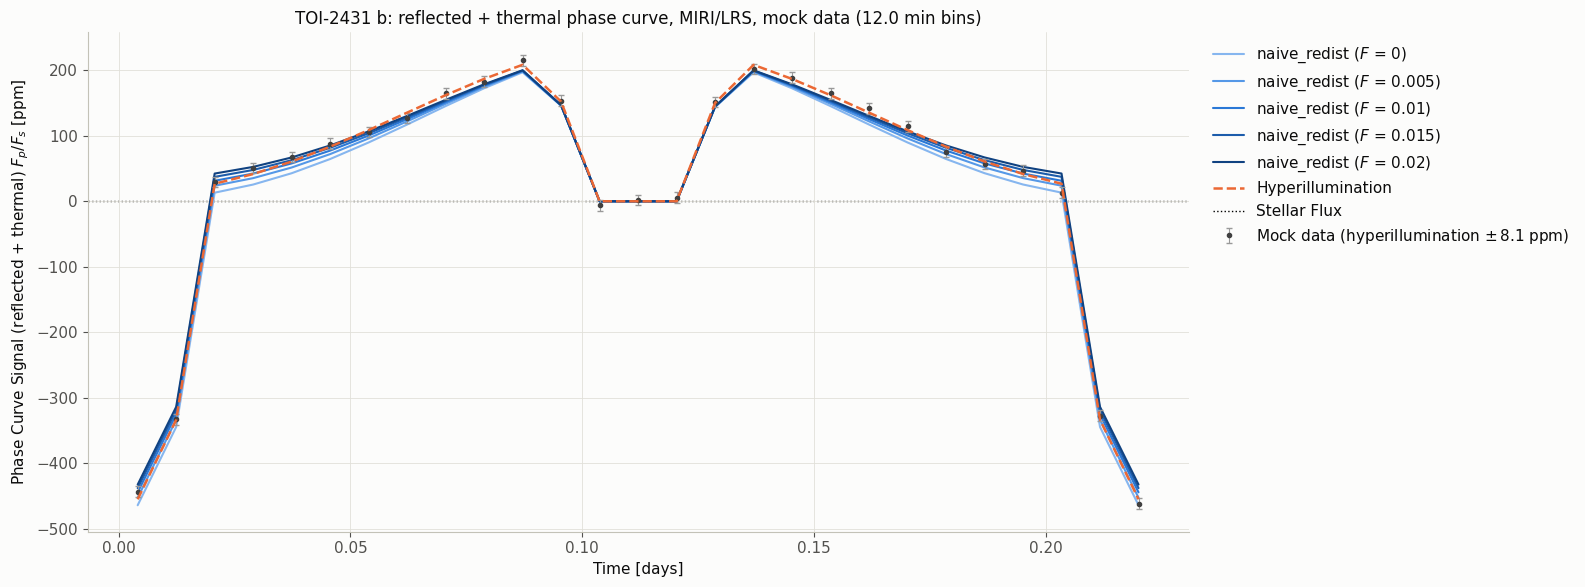

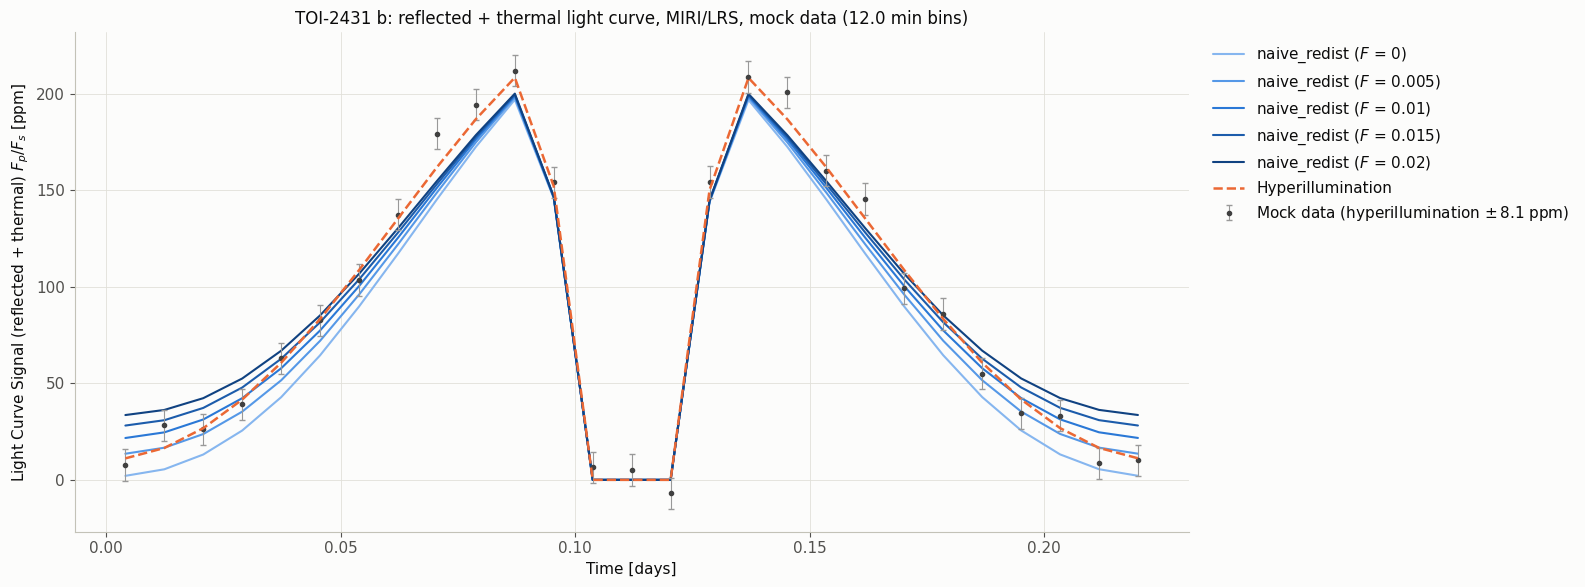

In [4]:
# Mock observation: at each binned time draw a data point ~ N(mean = hyperillum model, std = sigma_bin),
rng = np.random.default_rng(SEED)   # fixed seed -> reproducible mock data
# signal [ppm] of each curve for the two views: the phase curve with the transit, and the light curve without it
views = [("phase curve", r"Phase Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]", lambda pc, lc: (pc - 1) * 1e6),
         ("light curve", r"Light Curve Signal (reflected + thermal) $F_p/F_s$ [ppm]", lambda pc, lc: lc * 1e6)]

for name, ylabel, signal in views:
    tb_k, yb_k = bin_curve(t_k, signal(pc_k, lc_k), minutes_binning)   # hyperillumination model, binned [ppm]
    y_data = yb_k + rng.normal(0., sigma_bin, size=yb_k.size)          # mock data ~ N(hyperillum, sigma_bin)

    plt.figure(figsize=(16, 6))
    plt.errorbar(tb_k, y_data, yerr=sigma_bin, label=rf"Mock data (hyperillumination $\pm\,{sigma_bin:.1f}$ ppm)", **MOCK_KW)
    for F, col in zip(F_small, F_COLORS):
        t_F, pc_F, lc_F = redist_curves[F]
        plt.plot(*bin_curve(t_F, signal(pc_F, lc_F), minutes_binning), lw=1.5, color=col, label=f"naive_redist ($F$ = {F:g})")
    plt.plot(tb_k, yb_k, lw=1.8, ls="--", color=C_HI, label="Hyperillumination", zorder=6)
    if name == "phase curve": stellar_flux_line()   # only the view with the transit
    plt.xlabel("Time [days]")
    plt.ylabel(ylabel)
    plt.title(f"{planet.name}: reflected + thermal {name}, {instrument}, mock data ({minutes_binning:.1f} min bins)")
    plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1.))
    plt.tight_layout()
    plt.show()

## 2. Bias of the joint $A_B$ + $F$ fit

`fit_redist` next to `fit_naive`, both with the baseline free, with the nightside temperature the fitted $F$ implies. The figures show the best fits against the truth and the residuals before and after absorbing the bias.

In [5]:
# demo: fit naive (A_B only, as in 01_albedo_bias) and naive_redist (A_B and F) to the hyperillumination truth and report the recovered biases
_, truth = model_pcurve(cfg, "hyperillum", A_B_true)

# sqrt(chi2) is S_perp, the truth-to-manifold distance in sigma_bin units — NOT a sigma under any standard test.
# Fitted-vs-fitted discrimination: E[Lambda] = S_perp^2, sd = 2*S_perp, so the significance is S_perp/2. As goodness of fit: S_perp^2/sqrt(2*(n_bins-2)). Neither is the significance printed. bias/sigma is the criterion; this line is a distance.
A_fit, chi2, rms = fit_naive(cfg, truth)
A_fit2, F_fit2, chi2_2, rms_2 = fit_redist(cfg, truth)
T_night = float(surface_temperature(np.pi, planet, "naive_redist", A_B=A_fit2, F=F_fit2))   # nightside temperature the joint fit implies (the truth's antistellar point is at 0 K)
print(f"baseline free   ({cfg.n_orbits} orbits, {cfg.n_bins} bins)")
print(f"   A_B only : A_B {A_B_true:.3f} -> {A_fit:.3f}  bias={A_fit-A_B_true:+.3f} ({100*(A_fit-A_B_true)/A_B_true:+.1f}%)  "
      f"chi2={chi2:.3f}  resid_rms={rms:.2f} ppm  significance={np.sqrt(chi2):.2f} sigma")
print(f"   A_B and F: A_B {A_B_true:.3f} -> {A_fit2:.3f}  bias={A_fit2-A_B_true:+.3f} ({100*(A_fit2-A_B_true)/A_B_true:+.1f}%)  "
      f"chi2={chi2_2:.3f}  resid_rms={rms_2:.2f} ppm  significance={np.sqrt(chi2_2):.2f} sigma")
print(f"              F {F_true:g} -> {F_fit2:.4f} (bias={F_fit2-F_true:+.4f}, implied nightside T = {T_night:.0f} K)   "
      f"chi2 improvement from freeing F: {chi2 - chi2_2:.3f}")

baseline free   (5 orbits, 27 bins)
   A_B only : A_B 0.200 -> 0.140  bias=-0.060 (-29.9%)  chi2=12.635  resid_rms=5.57 ppm  significance=3.55 sigma
   A_B and F: A_B 0.200 -> 0.031  bias=-0.169 (-84.6%)  chi2=4.623  resid_rms=3.37 ppm  significance=2.15 sigma
              F 0 -> 0.0058 (bias=+0.0058, implied nightside T = 656 K)   chi2 improvement from freeing F: 8.013


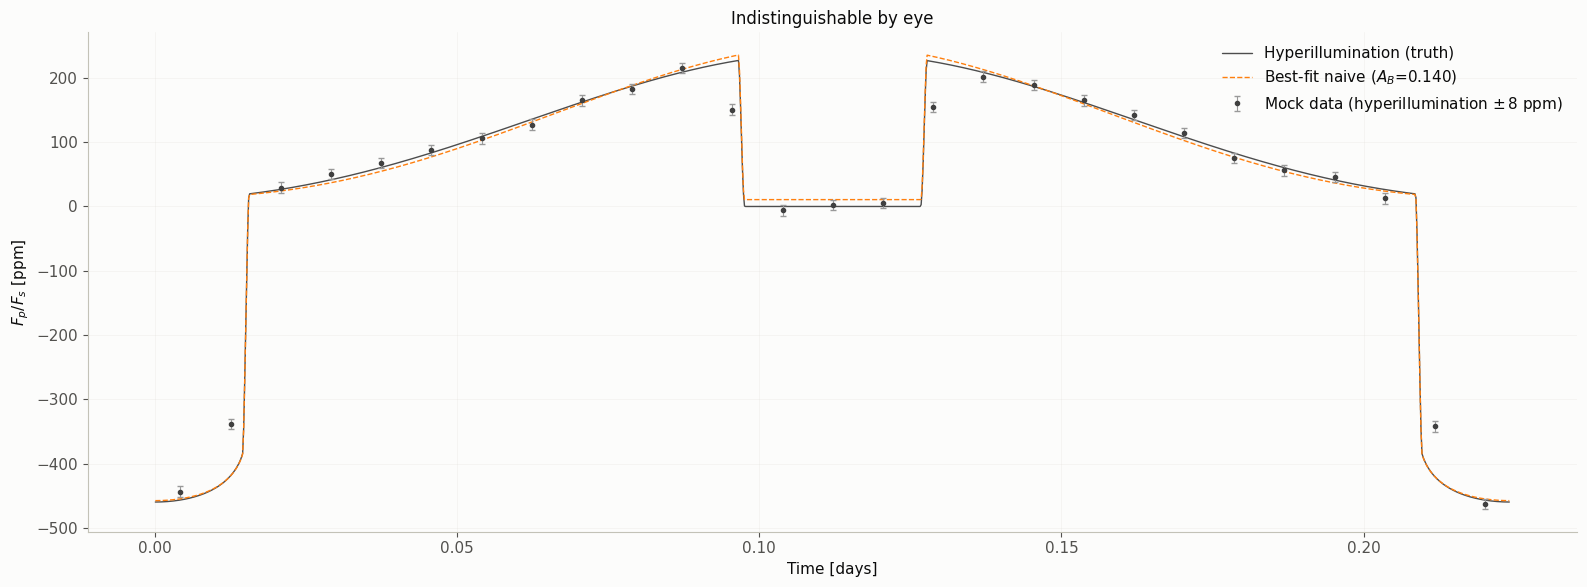

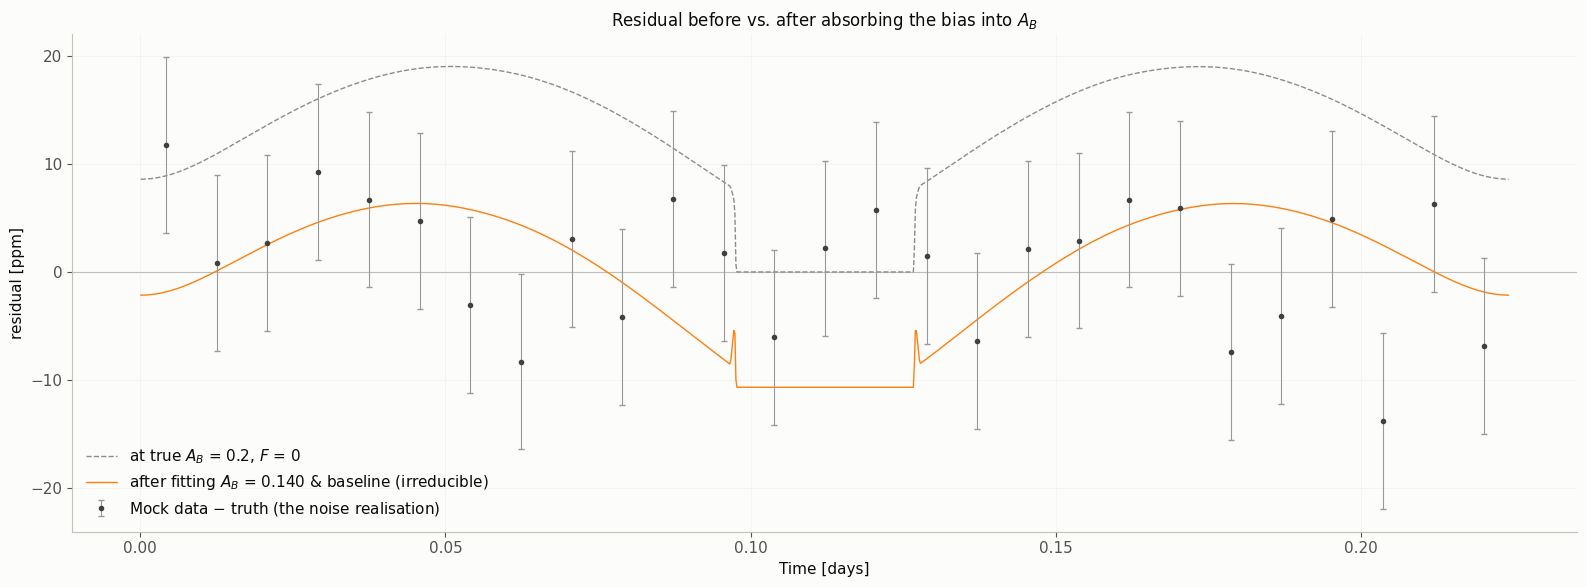

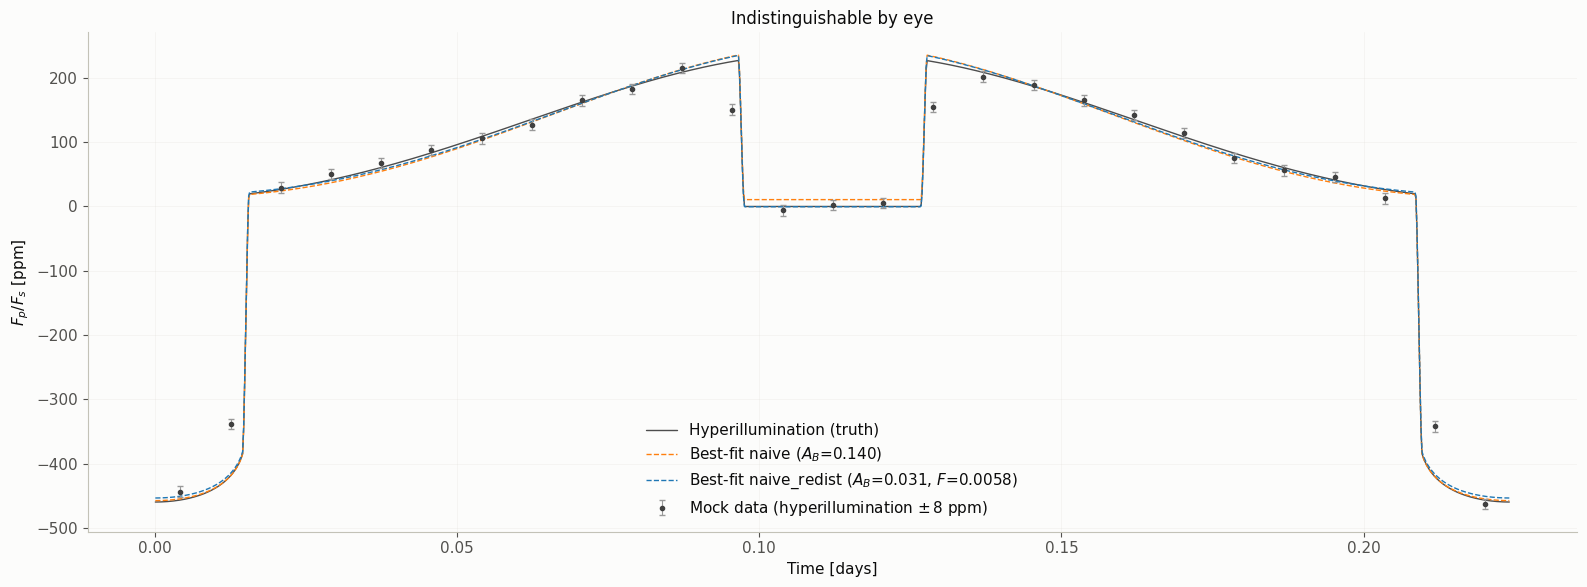

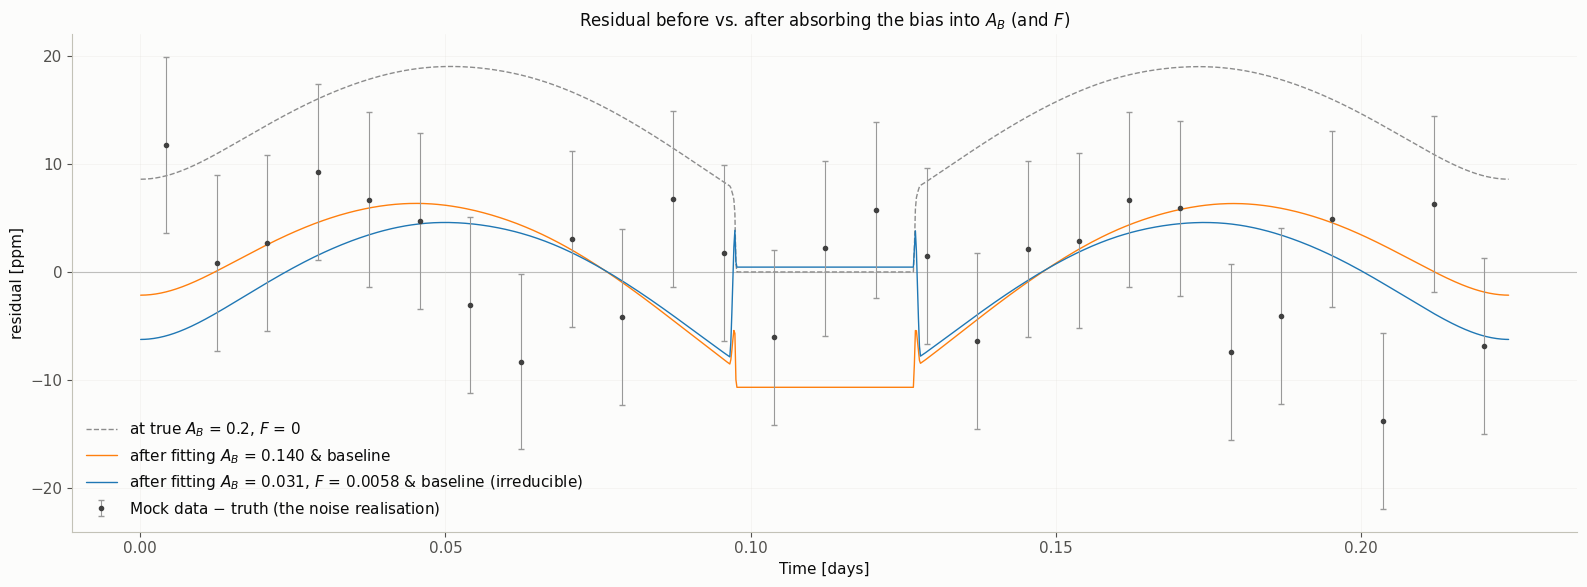

In [6]:
# before vs after absorbing the bias into A_B (naive) or into A_B and F (naive_redist)
t_, truth = model_pcurve(cfg, "hyperillum", A_B_true)
A_fit, _, _  = fit_naive(cfg, truth)
A_fit2, F_fit2, _, _ = fit_redist(cfg, truth)
naive_0   = model_pcurve(cfg, "naive", A_B_true)[1]   # at the true values: A_B_true, F = 0
naive_f   = model_pcurve(cfg, "naive", A_fit)[1]
naive_f   = naive_f + (truth - naive_f).mean()
redist_f  = model_pcurve(cfg, "naive_redist", A_fit2, F=F_fit2)[1]
redist_f  = redist_f + (truth - redist_f).mean()

# Mock observation, as in 1.: one draw ~ N(mean = hyperillumination truth, std = sigma_bin) per bin
tb, yb_truth = bin_curve(t_, truth, minutes_binning)
y_data = yb_truth + np.random.default_rng(SEED).normal(0., sigma_bin, size=yb_truth.size)   # same seed as the mock data in 1.

# Same two figures as 01_albedo_bias.ipynb section 2 (same colours), drawn twice: first without, then with the joint A_B + F fit.
C_TRUTH, C_TRUE_RESID, C_FIT, C_JOINT = "0.3", "0.55", "C1", "C0"   # truth (dark grey), residual at the true values (grey, dashed), A_B-only fit (orange), joint fit (blue)
for with_joint in (False, True):
    # Figure 1: truth vs best fit(s)
    fig, ax = plt.subplots(figsize=(16, 6))
    ax.errorbar(tb, y_data, yerr=sigma_bin, label=rf"Mock data (hyperillumination $\pm\,{sigma_bin:.0f}$ ppm)", **MOCK_KW)
    ax.plot(t_, truth,   lw=1, color=C_TRUTH, label="Hyperillumination (truth)")
    ax.plot(t_, naive_f, lw=1, ls="--", color=C_FIT, label=f"Best-fit naive ($A_B$={A_fit:.3f})")
    if with_joint:
        ax.plot(t_, redist_f, lw=1, ls="--", color=C_JOINT, label=f"Best-fit naive_redist ($A_B$={A_fit2:.3f}, $F$={F_fit2:.4f})")
    ax.set_ylabel(r"$F_p/F_s$ [ppm]"); ax.set_xlabel("Time [days]")
    ax.set_title("Indistinguishable by eye")
    ax.grid(alpha=.3); ax.legend()
    fig.tight_layout()
    plt.show()

    # Figure 2: residuals on one axes, with the same mock data as the noise the bias has to beat
    fig, ax = plt.subplots(figsize=(16, 6))
    ax.axhline(0., color="0.7", lw=.8, zorder=1)
    ax.errorbar(tb, y_data - yb_truth, yerr=sigma_bin, label=r"Mock data $-$ truth (the noise realisation)", **MOCK_KW)
    ax.plot(t_, truth - naive_0, lw=1, ls="--", color=C_TRUE_RESID, label=rf"at true $A_B$ = {A_B_true:.1f}, $F$ = 0")
    ax.plot(t_, truth - naive_f, lw=1, color=C_FIT, label=rf"after fitting $A_B$ = {A_fit:.3f} & baseline" + ("" if with_joint else " (irreducible)"))
    if with_joint:
        ax.plot(t_, truth - redist_f, lw=1, color=C_JOINT, label=rf"after fitting $A_B$ = {A_fit2:.3f}, $F$ = {F_fit2:.4f} & baseline (irreducible)")
    ax.set_ylabel("residual [ppm]"); ax.set_xlabel("Time [days]")
    ax.set_title(r"Residual before vs. after absorbing the bias into $A_B$" + (" (and $F$)" if with_joint else ""))
    ax.grid(alpha=.3); ax.legend()
    fig.tight_layout()
    plt.show()

The $\chi^2$ landscape of the joint fit on an $(A_B, F)$ grid (noiseless residual, baseline free). The contours mark $\Delta\chi^2 = 2.30$ and $6.18$ above the minimum: models inside them could not be told apart from the best fit at 68 % and 95 %.

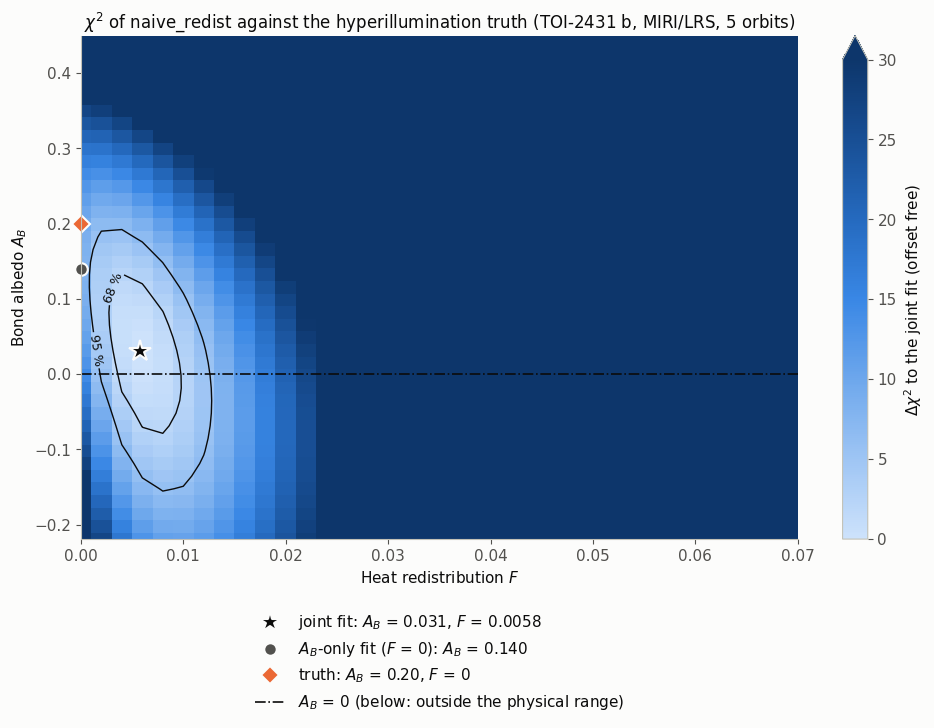

68 % region on the grid: A_B in [-0.07, 0.13],  F <= 0.008


In [7]:
F_MAX = 0.07   # plotted F range: widen it if the 95 % contour does not close inside the plot
# 0.25 below both fits (which can lie below A_B = 0, A_B_FIT_BOUNDS) up to 0.25 past the truth and both fits, so the grid survives config changes
AB_grid = np.linspace(max(A_B_FIT_BOUNDS[0], min(A_fit, A_fit2) - 0.25), min(A_B_FIT_BOUNDS[1], max(A_B_true, A_fit, A_fit2) + 0.25), 41)
F_grid = np.linspace(0., F_MAX, 36)
d_chi2 = chi2_landscape(cfg, truth, AB_grid, F_grid) - fit_chi2(cfg, truth, "naive_redist", A_fit2, F=F_fit2)   # relative to the joint best fit
# d_chi2 is referenced to the joint fit, not to the grid minimum, and plot_chi2_landscape has vmin=0 — an underconverged fit would be invisible. print(d_chi2.min()) must be >= 0.

fig, ax = plot_chi2_landscape(F_grid, AB_grid, d_chi2, F_MAX)
ax.plot(F_fit2, A_fit2, "*", ms=16, color=INK, mec="#fcfcfb", mew=1.5, label=f"joint fit: $A_B$ = {A_fit2:.3f}, $F$ = {F_fit2:.4f}")
ax.plot(0., A_fit, "o", ms=9, color=C_NAIVE, mec="#fcfcfb", mew=1.5, clip_on=False, label=f"$A_B$-only fit ($F$ = 0): $A_B$ = {A_fit:.3f}")
ax.plot(F_true, A_B_true, "D", ms=9, color=C_HI, mec="#fcfcfb", mew=1.5, clip_on=False, label=f"truth: $A_B$ = {A_B_true:.2f}, $F$ = 0")
if AB_grid[0] < 0.: ax.axhline(0., label="$A_B$ = 0 (below: outside the physical range)", **FIT_ZERO)
ax.set_title(f"$\\chi^2$ of naive_redist against the hyperillumination truth ({planet.name}, {instrument}, {cfg.n_orbits} orbits)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
plt.show()

if not (d_chi2 < 2.30).any():
    raise ValueError("68 % region is not on the grid: widen AB_grid or F_MAX")
(A_lo, A_hi), F_hi = chi2_region(d_chi2, AB_grid, F_grid)
print(f"68 % region on the grid: A_B in [{A_lo:.2f}, {A_hi:.2f}],  F <= {F_hi:.3f}")

## 3. Bias vs the true $A_B$

Both fits over a grid of true $A_B$, with the Fisher $\sigma$s and the measurability of both biases. Freeing $F$ enlarges the albedo bias, and the joint fit returns $F > 0$ (`fit_redist` scans $F$: a local optimizer started at $F = 0$ would stay on that bound and return the $A_B$-only fit). The fits are not bounded by the physical floor (`A_B_FIT_BOUNDS`); the output lists below which true $A_B$ they go below 0 (dash-dot line).

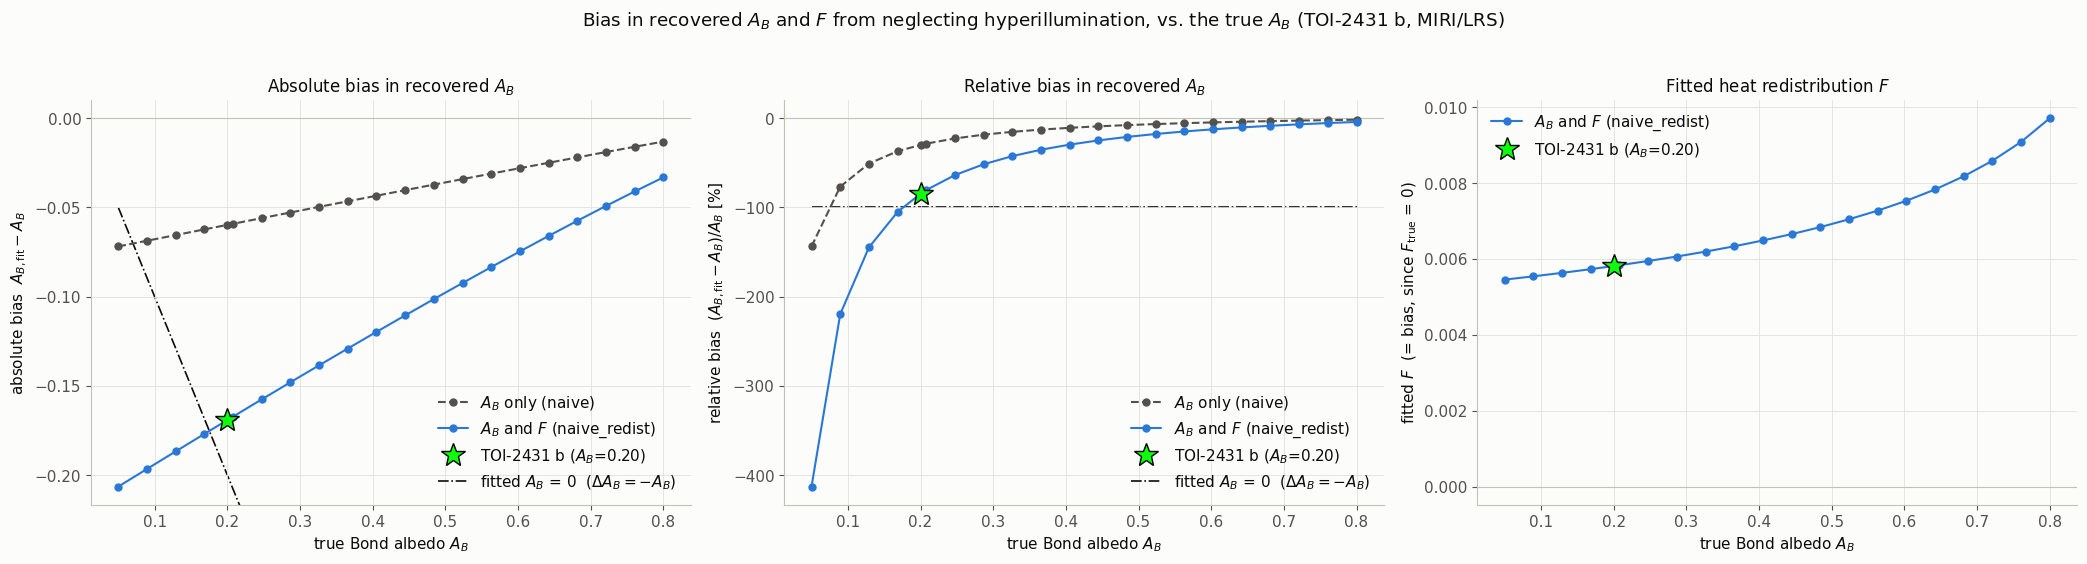

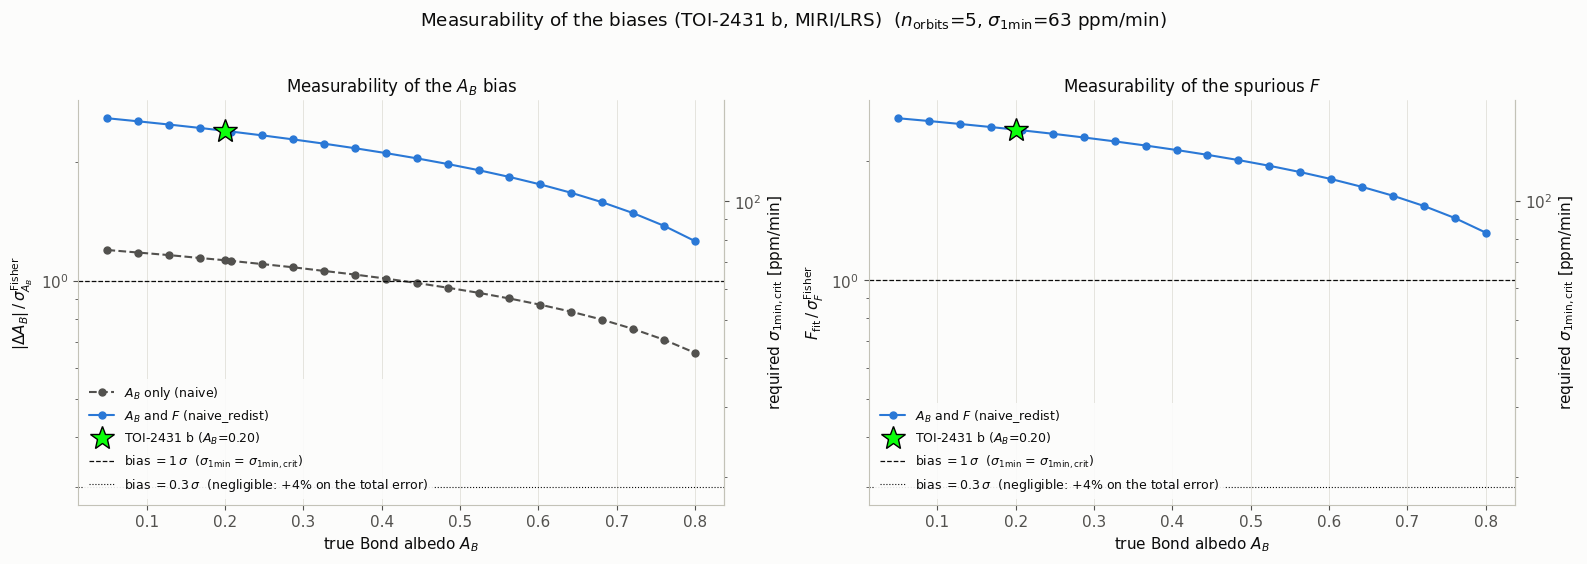

at TOI-2431 b: A_B-only bias -0.060,  joint bias -0.169 with F = 0.0058
A_B only fit below A_B = 0 for true A_B <= 0.05
joint    fit below A_B = 0 for true A_B <= 0.17
over the grid: F from 0.0055 to 0.0097,  joint / A_B-only bias from 2.5 to 2.9

|bias|/sigma_A_B at TOI-2431 b: 1.13 (A_B only), 2.40 (joint)   ->  sigma_1min_crit = 151.0 ppm/min vs 62.9 delivered  (0.4x finer, or 1 orbits instead of 5)
spurious redistribution: F = 0.0058 +- 0.0024  ->  2.41 sigma   (F_true = 0, so this is the false-atmosphere significance)


In [8]:
# Vary the TRUE Bond albedo and refit both models at each value (single target geometry, free baseline).
# Bias = fit - truth; the truth has F = 0, so the fitted F is the bias in F. Fisher sigmas (baseline marginalised) turn the biases into a measurability.
A_B_grid = np.unique(np.concatenate([np.linspace(0.05, 0.80, 20), [A_B_true]]))
# The fits are not railed at the physical floor (A_B_FIT_BOUNDS), so every point is a valid fit, also where the fitted A_B is below 0 (the dash-dot line; the output lists those points).
sweep = bias_vs_true_AB(cfg, A_B_grid, redist=True)
bias_naive, sig_naive = sweep["naive"]["bias_A_B"], sweep["naive"]["sigma_A_B"]
bias_joint, F_joint, sig_joint, sig_F = (sweep["naive_redist"][k] for k in ("bias_A_B", "F_fit", "sigma_A_B", "sigma_F"))
bs_naive, _ = measurability(bias_naive, sig_naive, cfg.sigma_1min)             # systematic in units of the statistical error bar, at the CURRENT sigma_1min
bs_joint, crit_joint = measurability(bias_joint, sig_joint, cfg.sigma_1min)
i0 = int(np.argmin(np.abs(A_B_grid - A_B_true)))   # nominal target point

# Freeing F widens A_B's MARGINAL sigma as well as enlarging its bias, so the two effects partly cancel -- which is why the ratio, not the bias alone, is the decision number.
target_label = f"{planet.name} ($A_B$={A_B_true:.2f})"
fig, _ = plot_joint_bias_vs_true_AB(A_B_grid, sweep, i0, target_label=target_label,
                                    title=f"Bias in recovered $A_B$ and $F$ from neglecting hyperillumination, vs. the true $A_B$ ({planet.name}, {instrument})")
plt.show()
# Measurability: |Delta A_B| / sigma_A_B (left) and the spurious F / sigma_F (right); the right axes give the per-minute precision at which each bias is a 1-sigma effect.
fig, _ = plot_joint_measurability(A_B_grid, sweep, i0, cfg, target_label=target_label,
                                  title=f"Measurability of the biases ({planet.name}, {instrument})")
plt.show()

below = {name: A_B_grid + b < 0. for name, b in (("A_B only", bias_naive), ("joint", bias_joint))}   # fits below the physical floor A_B = 0
print(f"at {planet.name}: A_B-only bias {bias_naive[i0]:+.3f},  joint bias {bias_joint[i0]:+.3f} with F = {F_joint[i0]:.4f}")
for name, r in below.items():
    print(f"{name:8s} fit below A_B = 0 for true A_B <= {A_B_grid[r].max():.2f}" if r.any() else f"{name:8s} fit at A_B >= 0 for every true A_B of the grid")
print(f"over the grid: F from {F_joint.min():.4f} to {F_joint.max():.4f},  joint / A_B-only bias from {np.min(bias_joint / bias_naive):.1f} to {np.max(bias_joint / bias_naive):.1f}")

fac = cfg.sigma_1min / crit_joint[i0]   # = 1 / bias_sigma; how much finer the photometry must get before the bias is a 1-sigma effect
print(f"\n|bias|/sigma_A_B at {planet.name}: {bs_naive[i0]:.2f} (A_B only), {bs_joint[i0]:.2f} (joint)"
      f"   ->  sigma_1min_crit = {crit_joint[i0]:.1f} ppm/min vs {cfg.sigma_1min:.1f} delivered"
      f"  ({fac:.1f}x finer, or {fac ** 2 * cfg.n_orbits:.0f} orbits instead of {cfg.n_orbits})")
print(f"spurious redistribution: F = {F_joint[i0]:.4f} +- {sig_F[i0]:.4f}  ->  {F_joint[i0] / sig_F[i0]:.2f} sigma   (F_true = 0, so this is the false-atmosphere significance)")

## 4. Bias vs inclination

The inclination sweep of `01_albedo_bias.ipynb` §4 (same grid rule) for both point-source fits, in MIRI/LRS and the joint NIRSpec fit at the planet's own noise: the bias of both fits, the spurious $F$ and its significance $z_F$ from a central to a near-grazing transit. Dashed: the $A_B$-only fit.

inclination grid: 68-90 deg (occultation >= 3 of 27 bins below 90 deg; grazing below 61.9 deg)



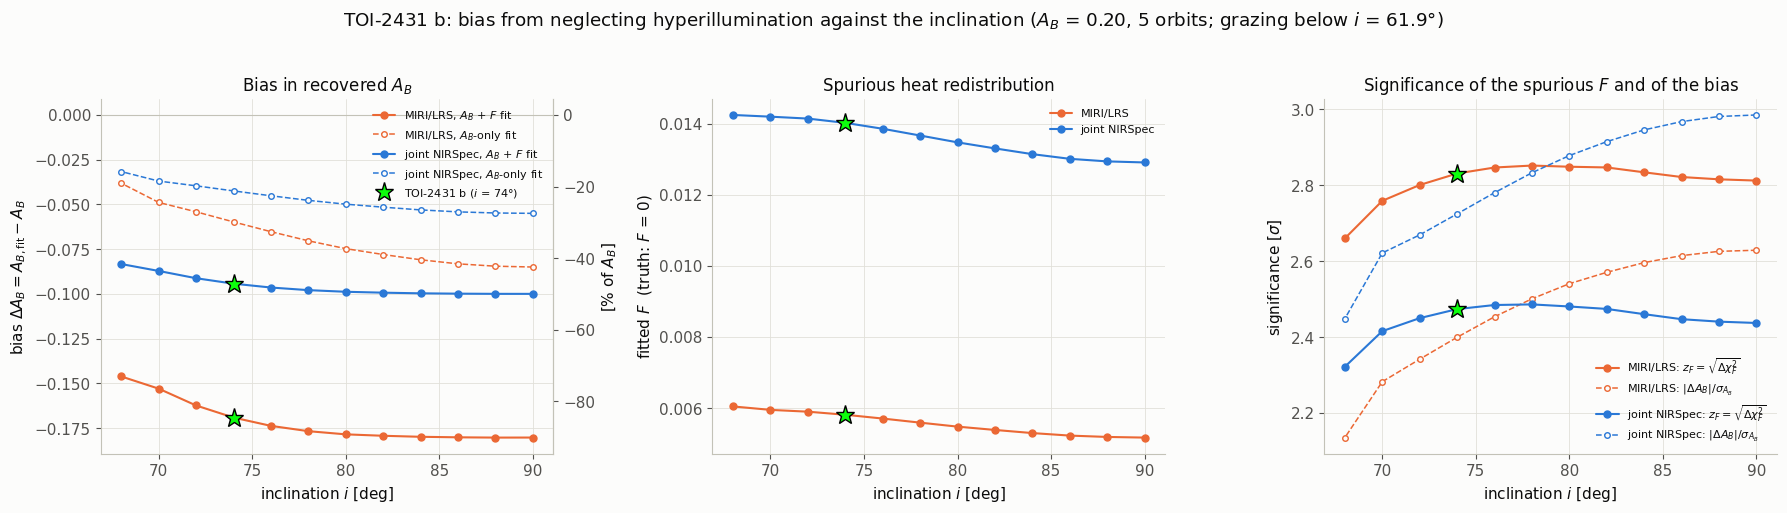

TOI-2431 b, MIRI/LRS  (value = inclination [deg])
 value  A_B_fit     bias   sigma  bias_sigma  A_B_fit_J  bias_J  sigma_J  bias_sigma_J    F_fit   z_F
    90    0.115   -0.085 0.05478       1.552    0.01969 -0.1803   0.0686         2.629 0.005171 2.812
    88   0.1155 -0.08453 0.05478       1.543    0.01967 -0.1803  0.06868         2.626 0.005189 2.815
    86   0.1168 -0.08321 0.05479       1.519    0.01982 -0.1802  0.06892         2.614 0.005227 2.821
    84   0.1191 -0.08095 0.05477       1.478    0.02011 -0.1799  0.06929         2.596 0.005298 2.834
    82    0.122   -0.078 0.05473       1.425    0.02068 -0.1793  0.06976          2.57 0.005386 2.847
    80   0.1253 -0.07472 0.05464       1.368    0.02148 -0.1785  0.07027          2.54 0.005479 2.848
    78   0.1297 -0.07034 0.05438       1.294    0.02325 -0.1767  0.07068         2.501 0.005591 2.852
    76   0.1348 -0.06524 0.05389       1.211    0.02622 -0.1738  0.07083         2.453 0.005706 2.846
    74   0.1402 -0.05978 0.05308

In [9]:
# Modes of the sweeps (sections 4 and 5): MIRI/LRS and the joint NIRSpec fit, each at the planet's own noise; independent of `instrument` above
SWEEP_MODES = {"MIRI/LRS": "MIRI/LRS", "joint NIRSpec": tuple(JWST_BANDS[:2])}
kw_sweep = dict(n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA)
sweep_cfgs = {label: retrieval_cfg(cfg, planet, ins) for label, ins in SWEEP_MODES.items()}

# Lowest inclination of the sweep: the occultation (as long as the transit on a circular orbit) must still span MIN_OCC_BINS phase bins; closer to grazing the fit depends on n_bins (checked in 01_albedo_bias.ipynb section 4)
MIN_OCC_BINS = 3
i_graze = np.degrees(np.arccos((1. - planet.r1 / planet.r2) / (planet.R / planet.r2)))   # b = 1 - Rp/R*: below it the occultation is grazing
i_whole = np.arange(np.ceil(i_graze), 90.5, 1.)   # whole degrees
long_enough = (transit_duration_t14(planet.period, planet.R / planet.r2, planet.r1 / planet.r2, pd.Series(i_whole)) >= MIN_OCC_BINS * planet.period * 24. / cfg.n_bins).to_numpy()
if not long_enough.any(): raise ValueError(f"the occultation spans fewer than {MIN_OCC_BINS} of {cfg.n_bins} bins even at i = 90 deg: lower MIN_OCC_BINS or raise n_bins")
i_min = i_whole[np.argmax(long_enough)]
if planet.incl < i_min: print(f"NOTE: the planet's own i = {planet.incl:g} deg is below the cut ({i_min:g} deg), so its own point depends on n_bins")
incl_grid = np.unique(np.concatenate([np.arange(90., i_min - 0.5, -2.), [i_min, planet.incl]]))[::-1]
print(f"inclination grid: {i_min:g}-90 deg (occultation >= {MIN_OCC_BINS} of {cfg.n_bins} bins below 90 deg; grazing below {i_graze:.1f} deg)\n")
sweeps_i = {label: bias_sweep(c, A_B_true, incl_grid, cfg_with_incl, **kw_sweep) for label, c in sweep_cfgs.items()}

fig, _ = plot_bias_sweep(sweeps_i, A_B_true, r"inclination $i$ [deg]", joint=True, mark=planet.incl, mark_label=f"{planet.name} ($i$ = {planet.incl:g}°)",
                         title=f"{planet.name}: bias from neglecting hyperillumination against the inclination ($A_B$ = {A_B_true:.2f}, {cfg.n_orbits} orbits; grazing below $i$ = {i_graze:.1f}°)")
plt.show()
for label, t in sweeps_i.items():
    print(f"{planet.name}, {label}  (value = inclination [deg])")
    print(t[["value", "A_B_fit", "bias", "sigma", "bias_sigma", "A_B_fit_J", "bias_J", "sigma_J", "bias_sigma_J", "F_fit", "z_F"]].to_string(index=False, float_format=lambda v: f"{v:.4g}"), "\n")

## 5. Bias vs the limb darkening $u_{\rm bol}$ of the irradiance

$u_{\rm bol}$ enters only the extended-source truth; the sweep changes it alone and refits both fits in the two modes of section 4.

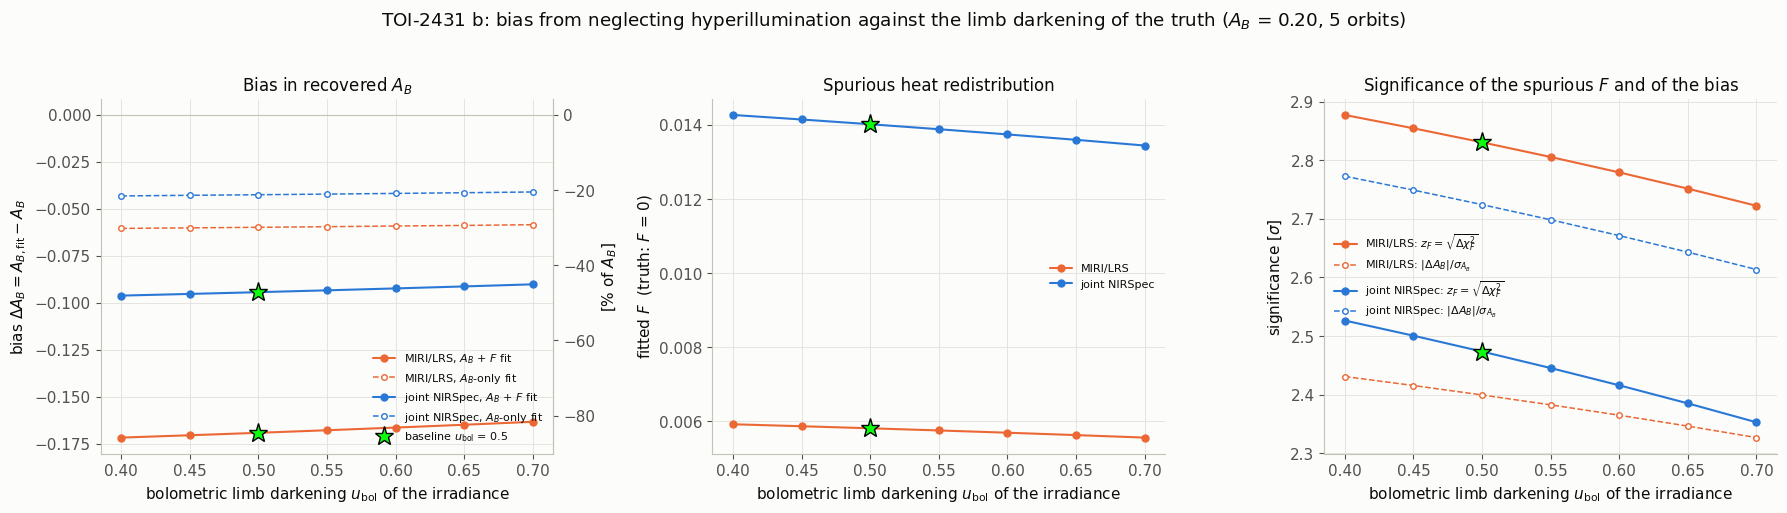

TOI-2431 b, MIRI/LRS  (value = u_bol)
 value  A_B_fit     bias   sigma  bias_sigma  A_B_fit_J  bias_J  sigma_J  bias_sigma_J    F_fit   z_F
   0.4   0.1396 -0.06038 0.05311       1.137    0.02831 -0.1717  0.07063         2.431 0.005921 2.877
  0.45   0.1399 -0.06008  0.0531       1.132    0.02956 -0.1704  0.07056         2.415 0.005868 2.855
   0.5   0.1402 -0.05978 0.05308       1.126    0.03086 -0.1691  0.07049         2.399 0.005813 2.831
  0.55   0.1405 -0.05946 0.05307       1.121    0.03222 -0.1678  0.07042         2.382 0.005755 2.806
   0.6   0.1409 -0.05909 0.05305       1.114    0.03365 -0.1664  0.07035         2.365 0.005693 2.779
  0.65   0.1412 -0.05878 0.05304       1.108    0.03514 -0.1649  0.07027         2.346 0.005629 2.752
   0.7   0.1416 -0.05839 0.05302       1.101    0.03671 -0.1633  0.07018         2.327 0.005562 2.722 

TOI-2431 b, joint NIRSpec  (value = u_bol)
 value  A_B_fit     bias   sigma  bias_sigma  A_B_fit_J   bias_J  sigma_J  bias_sigma_J   F_fit   z_F

In [10]:
u_bol_grid = np.unique(np.round(np.concatenate([np.arange(0.40, 0.701, 0.05), [u_bol]]), 6))
sweeps_u = {label: bias_sweep(c, A_B_true, u_bol_grid, cfg_with_u_bol, **kw_sweep) for label, c in sweep_cfgs.items()}

fig, _ = plot_bias_sweep(sweeps_u, A_B_true, r"bolometric limb darkening $u_{\rm bol}$ of the irradiance", joint=True, mark=u_bol, mark_label=f"baseline $u_{{\\rm bol}}$ = {u_bol:g}",
                         title=f"{planet.name}: bias from neglecting hyperillumination against the limb darkening of the truth ($A_B$ = {A_B_true:.2f}, {cfg.n_orbits} orbits)")
plt.show()
for label, t in sweeps_u.items():
    print(f"{planet.name}, {label}  (value = u_bol)")
    print(t[["value", "A_B_fit", "bias", "sigma", "bias_sigma", "A_B_fit_J", "bias_J", "sigma_J", "bias_sigma_J", "F_fit", "z_F"]].to_string(index=False, float_format=lambda v: f"{v:.4g}"), "\n")